# Do Game Awards move publisher stocks?
**An event study of The Game Awards, 2014–2025**

**Question.** When a game wins at The Game Awards, does the stock of the company that published (or developed) it move more than it otherwise would have?

**Design, fixed before looking at results**
- **Event:** each ceremony. *Day 0* is the first trading day **after** the ceremony on the stock's own exchange. The show airs Thursday evening Pacific time: after the US close, but during Friday trading in Tokyo and before the European open.
- **Normal return:** a market model (stock vs. its exchange's index), fitted on trading days −250 to −31.
- **Abnormal return (AR):** actual return minus normal return. **CAR** = cumulative AR over a window.
- **Primary outcome:** CAR over days 0 to +1 (the two sessions that can react to the results). Other windows are secondary.
- **Unit:** one observation per (ceremony, listed company). A company counts as nominated if any game it published **or** developed was nominated in a game category that year.
- **Groups:** *won an award*, *nominated, no win*, and *not nominated* (listed game companies with no nominations that year, a control for "game stocks on Game Awards weekend").
- **Main sample:** *pure-play* game companies (games are most of their revenue). An award can't visibly move Microsoft or Tencent.
- **Inference:** every company shares the same 12 event dates, so returns are correlated within a ceremony. Confidence intervals resample **whole ceremony years** (cluster bootstrap).

In [1]:
import sys, pathlib
root = pathlib.Path.cwd()          # works whether Jupyter starts in the project root or notebooks/
while not (root / "src").is_dir() and root != root.parent:
    root = root.parent
sys.path.insert(0, str(root))

import matplotlib.pyplot as plt
import pandas as pd
from src.event_study import (run_and_save, summarize, compare, regression,
                             CAR_WINDOWS, PRIMARY)
from src.plots import caar_chart, estimate_chart
from src.config import REPORTS

pd.set_option("display.float_format", "{:.3f}".format)
FIG = REPORTS / "figures"; FIG.mkdir(parents=True, exist_ok=True)

## 1. Build the panel
Abnormal returns for every listed parent company around every ceremony. Also writes `data/clean/event_study_obs.csv` and `event_study_daily_ar.csv` for the dashboards.

In [2]:
panel, daily, skipped = run_and_save()
print(f"{len(panel)} company-ceremony observations across {panel.year.nunique()} ceremonies")
print(f"{len(skipped)} skipped (company not listed yet / already delisted / too little history)")
panel.pivot_table(index="tier", columns="group", values="ticker", aggfunc="count", fill_value=0)

501 company-ceremony observations across 12 ceremonies
75 skipped (company not listed yet / already delisted / too little history)


group,nominee,not_nominated,winner
tier,,,
conglomerate,21,62,33
mixed,21,33,17
pure_play,83,176,55


## 2. Main result: pure-play game companies, CAR[0,+1]

In [3]:
pure = panel[panel.tier == "pure_play"]
main = summarize(pure, PRIMARY)
main[["group", "n_obs", "n_years", "mean_car_pct", "median_car_pct", "winsorized_mean_pct",
      "share_positive", "p_mean_positive", "bmp_z", "ci95_low_pct", "ci95_high_pct"]]

,group,n_obs,n_years,mean_car_pct,median_car_pct,winsorized_mean_pct,share_positive,p_mean_positive,bmp_z,ci95_low_pct,ci95_high_pct
0,nominee,83,12,0.159,-0.175,0.159,0.458,0.684,1.078,-0.498,0.903
1,not_nominated,176,12,0.314,0.104,0.281,0.511,0.860,0.840,-0.277,0.888
2,winner,55,12,-0.009,0.293,-0.009,0.509,0.504,-0.097,-0.948,0.999


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


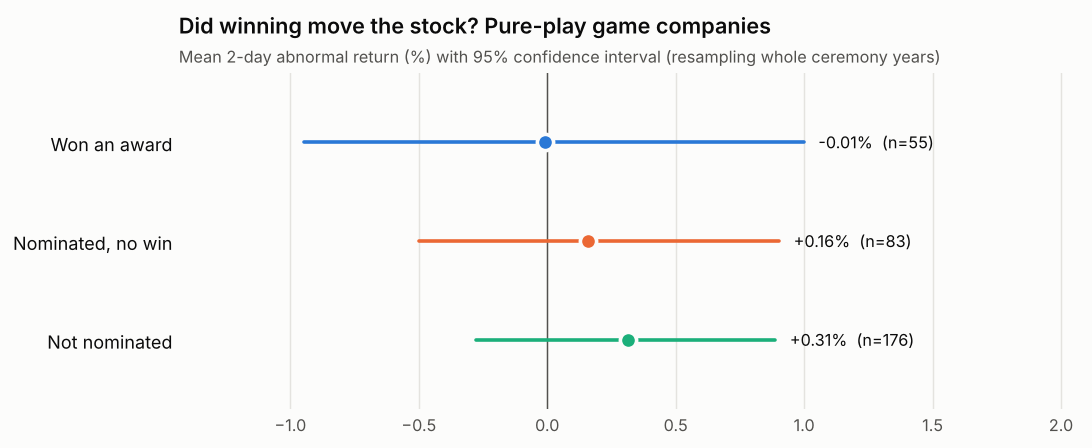

In [4]:
ax = estimate_chart(main, "Did winning move the stock? Pure-play game companies")
ax.figure.tight_layout(); ax.figure.savefig(FIG / "car01_by_group.png", dpi=160); plt.show()

**How to read it:** each dot is the average 2-day abnormal return for that group; the line is the 95% confidence interval. `share_positive` is the share of company-ceremonies with a positive return; `p_mean_positive` is the bootstrap probability that the group's true average is above zero. An interval that crosses zero means the data can't tell the effect apart from no effect.

## 3. The path around ceremony night

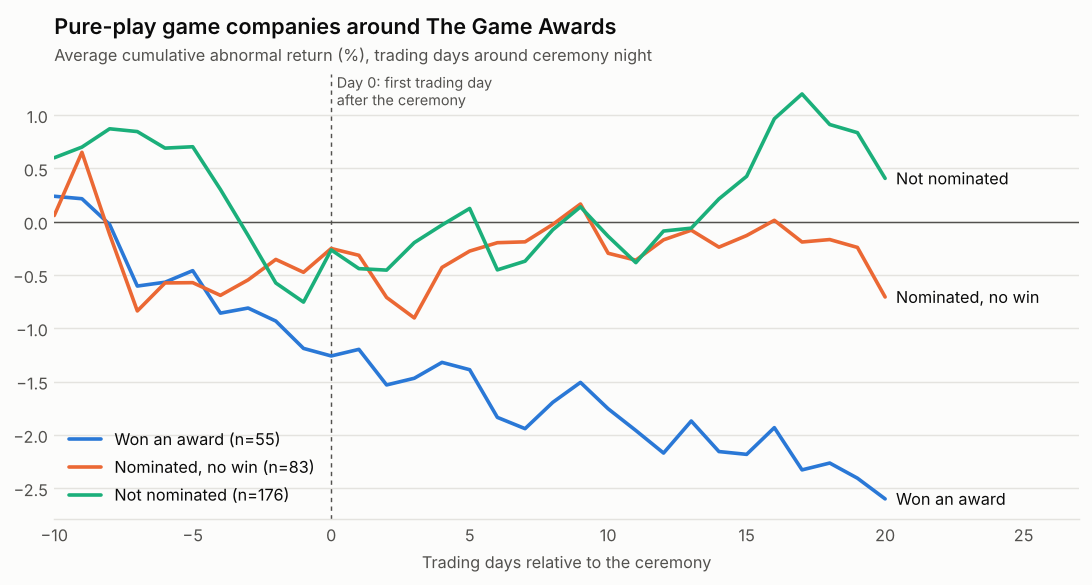

In [5]:
ax = caar_chart(daily[daily.tier == "pure_play"],
                "Pure-play game companies around The Game Awards")
ax.figure.tight_layout(); ax.figure.savefig(FIG / "caar_by_group.png", dpi=160); plt.show()

## 4. Head-to-head comparisons
Difference in mean CAR[0,+1], with a ceremony-year bootstrap. `p_diff_positive` is the probability the first group truly beats the second.

In [6]:
pure_n = pure.assign(nominated=pure.group.map({"winner": "nominated", "nominee": "nominated",
                                                "not_nominated": "not_nominated"}))
pd.DataFrame([
    compare(pure, "winner", "nominee"),
    compare(pure, "winner", "not_nominated"),
    compare(pure_n, "nominated", "not_nominated", by="nominated"),
])

,comparison,window,diff_pct,ci95_low_pct,ci95_high_pct,p_diff_positive
0,winner - nominee,car_0_1,-0.168,-1.250,0.835,0.390
1,winner - not_nominated,car_0_1,-0.323,-1.227,0.589,0.264
2,nominated - not_nominated,car_0_1,-0.222,-0.718,0.381,0.218


## 5. Robustness
### 5a. Every window (pure-play)
`car_pre_m5_m1` checks for leaks: movement in the week *before* the show.

In [7]:
rows = []
for w in CAR_WINDOWS:
    s = summarize(pure, w).assign(window=w)
    rows.append(s[["window", "group", "n_obs", "mean_car_pct", "winsorized_mean_pct",
                   "share_positive", "ci95_low_pct", "ci95_high_pct"]])
pd.concat(rows).pivot(index="group", columns="window", values="mean_car_pct")[list(CAR_WINDOWS)]

window,car_pre_m5_m1,car_0_0,car_0_1,car_0_5,car_0_20
group,,,,,
nominee,0.100,0.223,0.159,0.199,-0.232
not_nominated,-1.445,0.490,0.314,0.879,1.161
winner,-0.621,-0.071,-0.009,-0.200,-1.412


In [8]:
pd.concat(rows).set_index(["window", "group"])

n_obs  mean_car_pct  winsorized_mean_pct  \
window        group                                                     
car_pre_m5_m1 nominee           83         0.100               -0.274   
              not_nominated    176        -1.445               -1.278   
              winner            55        -0.621               -0.502   
car_0_0       nominee           83         0.223                0.233   
              not_nominated    176         0.490                0.534   
              winner            55        -0.071               -0.071   
car_0_1       nominee           83         0.159                0.159   
              not_nominated    176         0.314                0.281   
              winner            55        -0.009               -0.009   
car_0_5       nominee           83         0.199                0.465   
              not_nominated    176         0.879                0.649   
              winner            55        -0.200               -0.200   
car_0_20      nominee           83        -0.232               -0.232   
              not_nominated    176         1.161                0.825   
              winner            55        -1.412               -1.412   

                             share_positive  ci95_low_pct  ci95_high_pct  
window        group                                                       
car_pre_m5_m1 nominee                 0.422        -1.455          2.053  
              not_nominated           0.386        -2.562         -0.500  
              winner                  0.473        -2.241          0.853  
car_0_0       nominee                 0.518        -0.290          0.711  
              not_nominated           0.528         0.145          0.866  
              winner                  0.509        -0.767          0.669  
car_0_1       nominee                 0.458        -0.498          0.903  
              not_nominated           0.511        -0.277          0.888  
              winner                  0.509        -0.948          0.999  
car_0_5       nominee                 0.542        -1.297          2.040  
              not_nominated           0.489        -0.196          2.056  
              winner                  0.455        -1.417          1.350  
car_0_20      nominee                 0.434        -1.696          1.480  
              not_nominated           0.551        -1.114          3.496  
              winner                  0.400        -3.174          0.566

### 5b. By company type
If awards matter, the effect should be largest for pure-play companies and invisible for conglomerates.

In [9]:
by_tier = pd.concat([summarize(panel[panel.tier == t], PRIMARY).assign(tier=t)
                     for t in ["pure_play", "mixed", "conglomerate"]])
by_tier.set_index(["tier", "group"])[["n_obs", "mean_car_pct", "share_positive",
                                      "ci95_low_pct", "ci95_high_pct"]]

n_obs  mean_car_pct  share_positive  ci95_low_pct  \
tier         group                                                              
pure_play    nominee           83         0.159           0.458        -0.498   
             not_nominated    176         0.314           0.511        -0.277   
             winner            55        -0.009           0.509        -0.948   
mixed        nominee           21         0.443           0.524        -1.016   
             not_nominated     33        -0.642           0.455        -1.888   
             winner            17         1.197           0.647        -0.371   
conglomerate nominee           21        -0.533           0.381        -1.896   
             not_nominated     62         0.103           0.500        -0.573   
             winner            33         0.173           0.576        -0.288   

                            ci95_high_pct  
tier         group                         
pure_play    nominee                0.903  
             not_nominated          0.888  
             winner                 0.999  
mixed        nominee                1.915  
             not_nominated          0.585  
             winner                 2.984  
conglomerate nominee                0.624  
             not_nominated          0.793  
             winner                 0.655

### 5c. Regression: dose-response
CAR[0,+1] (%) on the number of wins and nominations and a Game of the Year win flag, pure-play and mixed companies. Standard errors are clustered by ceremony year (only 12 clusters, so treat p-values as approximate).

In [10]:
reg = regression(panel, PRIMARY)
print(reg.summary().tables[1])

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.1021      0.697      0.146      0.884      -1.265       1.469
n_wins        -0.2137      0.212     -1.006      0.314      -0.630       0.203
n_noms         0.0276      0.092      0.300      0.764      -0.153       0.208
goty_win_i     1.1758      0.865      1.359      0.174      -0.520       2.872
pure_play      0.1132      0.730      0.155      0.877      -1.317       1.543


## 6. Game of the Year winners, case by case

In [11]:
goty = panel[panel.goty_win].sort_values("year")
goty.assign(car_0_1_pct=100 * goty.car_0_1, car_0_5_pct=100 * goty.car_0_5)[
    ["year", "ticker", "parent_company", "tier", "roles", "car_0_1_pct", "car_0_5_pct", "games_won"]]

,year,ticker,parent_company,tier,roles,car_0_1_pct,car_0_5_pct,games_won
3,2014,EA,Electronic Arts,pure_play,publisher,-1.769,1.528,Dragon Age: Inquisition
58,2015,CDR.WA,CD Projekt,pure_play,publisher,3.130,0.895,The Witcher 3: Wild Hunt
76,2016,ATVI,Activision Blizzard,pure_play,publisher,1.662,-0.634,Overwatch
111,2017,7974.T,Nintendo,pure_play,publisher,-1.423,-4.678,Metroid: Samus Returns; Super Mario Odyssey; T...
149,2018,6758.T,Sony Group,conglomerate,publisher,-0.325,1.352,Astro Bot Rescue Mission; God of War
193,2019,ATVI,Activision Blizzard,pure_play,publisher,-0.894,-1.111,Call of Duty: Mobile; Call of Duty: Modern War...
202,2019,9468.T,Kadokawa,mixed,developer,0.289,3.956,Sekiro: Shadows Die Twice
233,2020,6758.T,Sony Group,conglomerate,publisher,-0.447,3.910,Ghost of Tsushima; The Last of Us Part II
278,2021,EA,Electronic Arts,pure_play,publisher,1.450,2.785,It Takes Two
328,2022,7832.T,Bandai Namco Holdings,mixed,publisher,0.720,-0.525,Elden Ring


Game of the Year winners with **no listed owner** (so no stock to test): *Baldur's Gate 3* (Larian, 2023) and *Clair Obscur: Expedition 33* (Sandfall / Kepler, 2025).

## 7. Findings

### Findings (full 2014–2025 data, 501 company-ceremony observations)

**1. Winning does not move the stock in any detectable way.** Pure-play winners average **−0.01%** over the two days after the ceremony (95% CI −0.95% to +1.00%). Half of winners rose and half fell (51% positive), and the bootstrap probability that the true average is above zero is **50%**, a coin flip.

**2. Being nominated doesn't either.** Nominees without a win average +0.16% and non-nominated game stocks +0.31%. Winners vs. nominees: −0.17 points (CI −1.25 to +0.84). Nominated vs. not nominated: −0.22 points (CI −0.72 to +0.38).

**3. The null is informative, not empty.** The intervals are narrow enough to **rule out an average 2-day effect larger than about ±1%** for pure-play winners. If awards created meaningful new information for investors, the data should have shown it.

**4. Game of the Year: positive but unproven.** In the regression, a GOTY win adds **+1.2 points** (p = 0.17); 6 of 12 GOTY-linked observations were positive. The two largest moves were *The Witcher 3* for CD Projekt (+3.1%, 2015) and *Elden Ring* for developer FromSoftware's parent Kadokawa (+4.8%, 2022). Suggestive, but 12 events can't confirm it.

**5. Company type behaves as expected.** Conglomerates (Sony, Microsoft, Tencent) show nothing; awards are rounding errors for them. Mixed companies (Kadokawa, Bandai Namco, Sega Sammy) show the largest winner average (+1.2%, CI −0.4% to +3.0%), carried mostly by Kadokawa's *Elden Ring* reaction.

**6. A pattern to watch, not a finding:** winners drift down about **−1.4%** over the 20 trading days after the show (CI −3.2% to +0.6%), consistent with "buy the rumor, sell the news," but not statistically distinguishable from zero.

**A note on chance:** the robustness tables test 15 group-by-window combinations, so about one should look "significant" at 5% by luck alone. Two do, and both are in the **non-nominated control group**: a −1.4% drift in the week *before* the show and a +0.5% bounce on day 0. Since these companies had no nominations, this isn't an award effect. It most likely reflects December moves in small game stocks that a broad market index doesn't capture, and it's exactly why the design compares winners to a control group rather than to zero.

**Bottom line:** markets treat The Game Awards as known or minor information. Nominees are public weeks in advance and winners are often expected, so prices react before the show or not at all. The more promising place to look for award effects is **sales and player counts**, the next stage of this project.

## 8. Limitations
- **Small sample of events.** 12 ceremonies; returns within a ceremony move together, so the effective sample is closer to 12 than to several hundred.
- **Award news is small relative to company value.** Even for pure-play firms, one award is a small slice of a multi-game portfolio. A null result means no detectable effect, not proof of zero effect.
- **Other news in the same week** (earnings, launches, deals) adds noise. Example: CD Projekt's −17.7% in December 2020 was the *Cyberpunk 2077* launch, not the awards. Winsorized means and medians limit the influence of such cases.
- **Coverage gaps:** Codemasters (2019–2020), Thunderful (2023) and Devolver (2021–2025) have no free price history after delisting (20 nominations). Private publishers (Valve, Epic, Annapurna, Larian, Kepler and others) have no stock to test.
- **Ceremony timing:** Day 0 is the first session after the ceremony; markets that were open during the show (e.g. Tokyo) may have partly reacted intraday.

## 9. Next steps
- **Nomination-announcement event** (mid-November): does *being nominated* move stocks, separately from winning?
- **Sales and player data** (Steam players around the ceremony), where awards may matter more than for stock prices.
- **Dashboards** in Power BI and Tableau from `event_study_obs.csv` and `event_study_daily_ar.csv`.